# Netflix Veri Temizleme Projesi (pandas + NumPy)

**Akış:** İş problemi → Yükleme → İnceleme → Kopya → Sütun/metin standardı → Tekrarlar → Hatalı değerler → Eksik değerler → Tip dönüşümü → Feature engineering → Tutarlılık/aykırı değer → Doğrulama → Kaydetme

## 0. İş problemini anla
Her satır Netflix'teki bir film veya dizi. Hedef: analize ve dashboard'a hazır, güvenilir bir tablo.

**Altın kurallar:** ham veriye dokunma · önce ölç, sonra değiştir · bilgi uydurma · her adımı kontrol et.

## 1. Kütüphaneler
`pandas` tablo işlemleri, `numpy` koşullu ve sayısal işlemler için.

In [1]:
# Bibliotheken importieren
from pathlib import Path

import numpy as np
import pandas as pd

# Anzeigeoptionen: alle Spalten anzeigen
pd.set_option("display.max_columns", None)

## 2. Veriyi yükle
Dosya notebook'un yanındaysa oradan, değilse GitHub'dan (raw link) okunur.

In [2]:
# Lokale Datei verwenden, sonst direkt von GitHub laden
LOCAL_FILE = Path("netflix_titles.csv")
URL = ("https://raw.githubusercontent.com/thepycoach/python-for-data-science/main/"
       "11.Project%203%20-%20Data%20Cleaning/netflix_titles.csv")

df_raw = pd.read_csv(LOCAL_FILE if LOCAL_FILE.exists() else URL)
df_raw.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 3. İlk inceleme
Boyut, tipler ve örnek satırlar. Burada henüz hiçbir şey değiştirmiyoruz.

In [3]:
# Form des Datensatzes (Zeilen, Spalten)
print("Shape:", df_raw.shape)

# Datentypen und Anzahl nicht fehlender Werte
df_raw.info()

Shape: (8807, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


In [4]:
# Zufällige Stichprobe ansehen (random_state macht sie reproduzierbar)
df_raw.sample(5, random_state=42)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
4970,s4971,Movie,"Game Over, Man!",Kyle Newacheck,"Adam DeVine, Anders Holm, Blake Anderson, Utka...",United States,"March 23, 2018",2018,TV-MA,102 min,"Action & Adventure, Comedies",Three buddies with big dreams go from underach...
3362,s3363,Movie,Arsenio Hall: Smart & Classy,Brian Volk-Weiss,Arsenio Hall,United States,"October 29, 2019",2019,TV-MA,63 min,Stand-Up Comedy,"In his first stand-up special, Arsenio Hall di..."
5494,s5495,TV Show,Kazoops!,NaN,"Reece Pockney, Scott Langley, Alex Babic, Gemm...",Australia,"May 5, 2017",2017,TV-Y,3 Seasons,Kids' TV,Music meets imagination in this inventive anim...
1688,s1689,TV Show,We Are the Champions,NaN,NaN,United States,"November 17, 2020",2020,TV-MA,1 Season,"Docuseries, Reality TV","Explore an array of unique competitions, from ..."
1349,s1350,TV Show,"Pablo Escobar, el patrón del mal",NaN,"Andrés Parra, Angie Cepeda, Cecilia Navia, Vic...",Colombia,"February 3, 2021",2012,TV-MA,1 Season,"Crime TV Shows, International TV Shows, Spanis...",From his days as a petty thief to becoming hea...


In [5]:
# Statistik für alle Spalten
df_raw.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
show_id,8807,8807,s1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
type,8807,2,Movie,6131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
title,8807,8807,Dick Johnson Is Dead,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
director,6173,4528,Rajiv Chilaka,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cast,7982,7692,David Attenborough,19,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,7976,748,United States,2818,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date_added,8797,1767,"January 1, 2020",109,NaN,NaN,NaN,NaN,NaN,NaN,NaN
release_year,8807.0,NaN,NaN,NaN,2014.180198,8.819312,1925.0,2013.0,2017.0,2019.0,2021.0
rating,8803,17,TV-MA,3207,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration,8804,220,1 Season,1793,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Veri kalitesi raporu
Eksik değer sayısı/yüzdesi, benzersiz değer sayısı ve tekrarlar.

In [6]:
# Qualitätsbericht pro Spalte erstellen
quality_report = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing": df_raw.isna().sum(),
    "missing_pct": (df_raw.isna().mean() * 100).round(2),
    "unique": df_raw.nunique(),
}).sort_values("missing", ascending=False)
quality_report

,dtype,missing,missing_pct,unique
director,object,2634,29.91,4528
country,object,831,9.44,748
cast,object,825,9.37,7692
date_added,object,10,0.11,1767
rating,object,4,0.05,17
duration,object,3,0.03,220
show_id,object,0,0.00,8807
type,object,0,0.00,2
title,object,0,0.00,8807
release_year,int64,0,0.00,74


In [7]:
# Duplikate prüfen: komplette Zeilen, ID und fachlicher Schlüssel
print("Doppelte Zeilen:", df_raw.duplicated().sum())
print("Doppelte show_id:", df_raw["show_id"].duplicated().sum())
print("Doppelt (title, type, release_year):",
      df_raw.duplicated(subset=["title", "type", "release_year"]).sum())

Doppelte Zeilen: 0
Doppelte show_id: 0
Doppelt (title, type, release_year): 0


In [8]:
# Häufigkeiten kategorialer Spalten: hier fallen falsche Werte auf
print(df_raw["type"].value_counts(dropna=False), end="\n\n")
print(df_raw["rating"].value_counts(dropna=False))

type
Movie      6131
TV Show    2676
Name: count, dtype: int64

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


**Bulgu:** `rating` sütununda `74 min`, `84 min`, `66 min` var. Bunlar yaş sınıfı değil, süre; yanlış sütuna kaymış.

## 5. Çalışma kopyası ve sütun adları

In [9]:
# Rohdaten unverändert lassen und auf einer Kopie arbeiten
df = df_raw.copy()

# Spaltennamen vereinheitlichen (snake_case)
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

# Verständlichere Namen vergeben
df = df.rename(columns={"listed_in": "genres", "cast": "cast_members"})
df.columns.tolist()

['show_id',
 'type',
 'title',
 'director',
 'cast_members',
 'country',
 'date_added',
 'release_year',
 'rating',
 'duration',
 'genres',
 'description']

## 6. Metin temizliği
Baştaki/sondaki boşluklar, çift boşluklar, görünmez karakterler ve listelerin kenarındaki fazla virgüller.

In [10]:
# Alle Textspalten ermitteln
text_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]

for col in text_cols:
    df[col] = (df[col]
               .str.replace("\u200b", "", regex=False)   # unsichtbare Zeichen entfernen
               .str.replace(r"\s+", " ", regex=True)      # mehrfache Leerzeichen reduzieren
               .str.strip())                              # Ränder bereinigen

# Überflüssige Kommas am Anfang/Ende von Listenspalten entfernen
list_cols = ["director", "cast_members", "country", "genres"]
for col in list_cols:
    df[col] = df[col].str.replace(r"^[,\s]+|[,\s]+$", "", regex=True)

# Leere Zeichenketten als fehlende Werte behandeln
df[text_cols] = df[text_cols].replace("", np.nan)

## 7. Tekrarları sil
Bu veride tekrar yok, ama adım her projede bulunmalı. Silmeden önce ve sonra say.

In [11]:
# Duplikate entfernen und Anzahl protokollieren
rows_before = len(df)
df = df.drop_duplicates()
df = df.drop_duplicates(subset="show_id", keep="first")
print("Entfernte Zeilen:", rows_before - len(df))

Entfernte Zeilen: 0


## 8. Yanlış sütundaki değerleri düzelt
Boolean mask ile hatalı satırları bul, değeri `duration`a taşı, `rating`i boşalt.

In [12]:
# Zeilen finden, in denen eine Dauer im Rating steht
mask_wrong = df["rating"].str.fullmatch(r"\d+ min", na=False) & df["duration"].isna()
display(df.loc[mask_wrong, ["title", "rating", "duration"]])

# Wert verschieben und falsches Rating löschen
df.loc[mask_wrong, "duration"] = df.loc[mask_wrong, "rating"]
df.loc[mask_wrong, "rating"] = np.nan

# NR (Not Rated) und UR (Unrated) bedeuten dasselbe
df["rating"] = df["rating"].replace({"UR": "NR"})

,title,rating,duration
5541,Louis C.K. 2017,74 min,NaN
5794,Louis C.K.: Hilarious,84 min,NaN
5813,Louis C.K.: Live at the Comedy Store,66 min,NaN


## 9. Eksik değerler
| Sütun | Karar | Neden |
|---|---|---|
| director, cast_members, country | `Unknown` | Oran yüksek, silmek veri kaybı olur |
| rating | `Unknown` | Çok az; gerçek değeri bilmiyoruz |
| date_added | boş bırak (`NaT`) | Tarih uydurulmaz |

Ülkeyi mod (en sık değer) ile doldurmak yüzlerce yapımı yanlışlıkla ABD yapardı. Eksiklik bilgisini kaybetmemek için önce bayrak sütunu ekliyoruz.

In [13]:
fill_cols = ["director", "cast_members", "country", "rating"]

# Markieren, wo ursprünglich Werte gefehlt haben
for col in ["director", "cast_members", "country"]:
    df[f"{col}_missing"] = df[col].isna()

# Fehlende Texte mit "Unknown" ersetzen
df[fill_cols] = df[fill_cols].fillna("Unknown")
df.isna().sum()

show_id                  0
type                     0
title                    0
director                 0
cast_members             0
country                  0
date_added              10
release_year             0
rating                   0
duration                 0
genres                   0
description              0
director_missing         0
cast_members_missing     0
country_missing          0
dtype: int64

## 10. Veri tipi dönüşümleri
`date_added` metin → tarih. `errors="coerce"` çevrilemeyeni `NaT` yapar; bu yüzden dönüşümden sonra kayıp olup olmadığını kontrol ediyoruz.

In [14]:
# Datum konvertieren (Format z. B. "September 25, 2021")
missing_before = df["date_added"].isna().sum()
df["date_added"] = pd.to_datetime(df["date_added"], format="%B %d, %Y", errors="coerce")

# Kontrolle: Es dürfen keine neuen fehlenden Werte entstanden sein
assert df["date_added"].isna().sum() == missing_before
print(df["date_added"].min(), "->", df["date_added"].max())

2008-01-01 00:00:00 -> 2021-09-25 00:00:00


## 11. `duration` sütununu ayır
`90 min` ve `2 Seasons` farklı birimler. Tek sayısal sütunda karışırsa ortalama anlamsız olur, bu yüzden iki sütun yapıyoruz.

In [15]:
# Zahl aus dem Text extrahieren
duration_value = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")

# Getrennte Spalten für Filme (Minuten) und Serien (Staffeln); Int16 erlaubt fehlende Werte
df["duration_min"] = duration_value.where(df["type"].eq("Movie")).astype("Int16")
df["season_count"] = duration_value.where(df["type"].eq("TV Show")).astype("Int16")
df[["type", "duration", "duration_min", "season_count"]].sample(6, random_state=1)

,type,duration,duration_min,season_count
2894,TV Show,1 Season,<NA>,1
2161,Movie,72 min,72,<NA>
6363,Movie,74 min,74,<NA>
2575,TV Show,1 Season,<NA>,1
2698,TV Show,2 Seasons,<NA>,2
7223,Movie,96 min,96,<NA>


## 12. Feature engineering
Analizde işe yarayacak yeni sütunlar.

In [16]:
# Datumsbestandteile
df["year_added"] = df["date_added"].dt.year.astype("Int16")
df["month_added"] = df["date_added"].dt.month.astype("Int8")

# Jahre zwischen Veröffentlichung und Aufnahme bei Netflix
df["years_to_netflix"] = df["year_added"] - df["release_year"]

# Hauptland und Hauptgenre (jeweils erster Eintrag der Liste)
df["main_country"] = df["country"].str.split(",").str[0].str.strip()
df["main_genre"] = df["genres"].str.split(",").str[0].str.strip()

# Zielgruppe aus dem Rating ableiten (np.select = mehrere Bedingungen)
conditions = [
    df["rating"].isin(["TV-Y", "TV-Y7", "TV-Y7-FV", "G", "TV-G"]),
    df["rating"].isin(["PG", "TV-PG"]),
    df["rating"].isin(["PG-13", "TV-14"]),
    df["rating"].isin(["R", "NC-17", "TV-MA"]),
]
choices = ["Kids", "Family", "Teens", "Adults"]
df["audience"] = np.select(conditions, choices, default="Unknown")

## 13. Mantık ve aykırı değer kontrolü
Bir yapım, yayın yılından önce eklenmiş görünüyorsa şüphelidir. Aykırı değerleri **silmiyoruz**, işaretliyoruz: 3 dakikalık kısa film ya da 5 saatlik yapım gerçek olabilir.

In [17]:
# Unlogisch: vor dem Erscheinungsjahr hinzugefügt
df["date_conflict"] = df["years_to_netflix"].lt(0).fillna(False).astype(bool)
print("Datumskonflikte:", df["date_conflict"].sum())
df.loc[df["date_conflict"], ["title", "type", "release_year", "date_added"]].head()

Datumskonflikte: 14


,title,type,release_year,date_added
1551,Hilda,TV Show,2021,2020-12-14
1696,Polly Pocket,TV Show,2021,2020-11-15
2920,Love Is Blind,TV Show,2021,2020-02-13
3168,Fuller House,TV Show,2020,2019-12-06
3287,Maradona in Mexico,TV Show,2020,2019-11-13


In [18]:
# Ausreißer bei der Filmdauer mit der IQR-Methode
movie_minutes = df["duration_min"].dropna().to_numpy(dtype=float)
q1, q3 = np.percentile(movie_minutes, [25, 75])
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr

df["duration_outlier"] = (
    (df["duration_min"].lt(lower) | df["duration_min"].gt(upper)).fillna(False).astype(bool)
)
print(f"Grenzen: {lower:.1f} - {upper:.1f} Minuten")
print("Ausreißer:", df["duration_outlier"].sum())
df.loc[df["duration_outlier"]].sort_values("duration_min")[["title", "duration_min"]].iloc[[0, 1, -2, -1]]

Grenzen: 46.5 - 154.5 Minuten
Ausreißer: 450


,title,duration_min
3777,Silent,3
2713,Sol Levante,5
717,Headspace: Unwind Your Mind,273
4253,Black Mirror: Bandersnatch,312


## 14. Bellek için kategorik tipler
Az sayıda tekrar eden değere sahip sütunlar `category` olur.

In [19]:
memory_before = df.memory_usage(deep=True).sum() / 1024**2

for col in ["type", "rating", "audience"]:
    df[col] = df[col].astype("category")

memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"Speicher: {memory_before:.2f} MB -> {memory_after:.2f} MB")

Speicher: 9.29 MB -> 7.95 MB


## 15. Çok değerli sütunlar (`explode`)
`"United States, India"` tek hücrede iki bilgi. Ülke/tür analizi için her değeri ayrı satıra alan yardımcı tablolar kurulur. Ana tablo bir satır = bir yapım olarak kalır.

In [20]:
def explode_column(data, col):
    """Zerlegt eine kommagetrennte Spalte in eine Zeile pro Wert."""
    result = data[["show_id", col]].assign(**{col: data[col].str.split(",")}).explode(col)
    result[col] = result[col].str.strip()
    return result.drop_duplicates().reset_index(drop=True)

df_countries = explode_column(df, "country")
df_genres = explode_column(df, "genres")
df_countries["country"].value_counts().head(10)

country
United States     3690
India             1046
Unknown            831
United Kingdom     806
Canada             445
France             393
Japan              318
Spain              232
South Korea        231
Germany            226
Name: count, dtype: int64

## 16. Son doğrulama
`assert` bir kural bozulursa kodu durdurur. Profesyonel projeyi ayıran adım budur.

In [21]:
# Qualitätsregeln automatisch prüfen
assert len(df) == len(df_raw), "Unerwarteter Zeilenverlust"
assert df["show_id"].is_unique, "show_id ist nicht eindeutig"
assert df[fill_cols].notna().all().all(), "Fehlende Werte in gefüllten Spalten"
assert not df["rating"].astype(str).str.contains("min").any(), "Dauer steht im Rating"
assert df.loc[df["type"] == "Movie", "duration_min"].notna().all(), "Film ohne Dauer"
assert df.loc[df["type"] == "TV Show", "season_count"].notna().all(), "Serie ohne Staffelzahl"
assert df["release_year"].between(1900, df_raw["release_year"].max()).all(), "Ungültiges Jahr"
print("Alle Prüfungen bestanden")
df.info()

Alle Prüfungen bestanden
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   show_id               8807 non-null   object        
 1   type                  8807 non-null   category      
 2   title                 8807 non-null   object        
 3   director              8807 non-null   object        
 4   cast_members          8807 non-null   object        
 5   country               8807 non-null   object        
 6   date_added            8797 non-null   datetime64[ns]
 7   release_year          8807 non-null   int64         
 8   rating                8807 non-null   category      
 9   duration              8807 non-null   object        
 10  genres                8807 non-null   object        
 11  description           8807 non-null   object        
 12  director_missing      8807 non-null   bool         

## 17. Kaydet
CSV her yerde açılır ama tipleri (tarih, category) saklamaz; tekrar okurken `parse_dates` gerekir.

In [22]:
# Ausgabeordner anlegen und bereinigte Daten speichern
output_dir = Path("data_clean")
output_dir.mkdir(exist_ok=True)

df.to_csv(output_dir / "netflix_clean.csv", index=False)
df_countries.to_csv(output_dir / "netflix_countries.csv", index=False)
df_genres.to_csv(output_dir / "netflix_genres.csv", index=False)

# Kontrolle durch erneutes Einlesen
check = pd.read_csv(output_dir / "netflix_clean.csv", parse_dates=["date_added"])
assert check.shape == df.shape
print("Gespeichert:", check.shape)

Gespeichert: (8807, 25)


## 18. Özet ve portfolyo için sonraki adımlar
- Yanlış sütuna kaymış süre değerleri düzeltildi.
- Metinler standartlaştırıldı, eksikler gerekçeli şekilde ele alındı ve bayraklandı.
- Tarih ve süre sayısal analize uygun hale getirildi.
- Tarih çelişkileri ve aykırı süreler silinmeden işaretlendi.

## 19. Kalan NaN değerlerini sil
Önce ölç: hangi sütunda NaN var ve neden?

- `date_added`, `year_added`, `month_added`, `years_to_netflix`: **gerçek eksik** (aynı satırlar) → sil.
- `duration_min` dizilerde, `season_count` filmlerde boş: **yapısal eksik**. Dizinin film süresi olmaz.

Bu yüzden düz `df.dropna()` her satırı siler!

In [23]:
# Verbleibende fehlende Werte anzeigen
remaining = df.isna().sum()
print(remaining[remaining > 0])

# Warnbeispiel: dropna() ohne subset entfernt alle Zeilen
print("Zeilen nach df.dropna():", len(df.dropna()))

date_added            10
duration_min        2676
season_count        6131
year_added            10
month_added           10
years_to_netflix      10
dtype: int64
Zeilen nach df.dropna(): 0


In [24]:
# Nur Zeilen mit echtem fehlenden Wert entfernen
df_viz = df.dropna(subset=["date_added"]).copy()
print("Entfernt:", len(df) - len(df_viz), "| Verbleibend:", len(df_viz))

# Filme und Serien trennen und die jeweils irrelevante Spalte entfernen
df_movies = df_viz[df_viz["type"] == "Movie"].drop(columns="season_count")
df_shows = df_viz[df_viz["type"] == "TV Show"].drop(columns="duration_min")

# Kontrolle: keine fehlenden Werte mehr
assert df_movies.isna().sum().sum() == 0
assert df_shows.isna().sum().sum() == 0
print("Filme:", df_movies.shape, "| Serien:", df_shows.shape)

Entfernt: 10 | Verbleibend: 8797
Filme: (6131, 24) | Serien: (2666, 24)


**`Unknown` satırları?** Onlar artık NaN değil. Hepsini silmek yerine yalnızca ilgili grafikte dışarıda bırakıyoruz. Kaybın büyüklüğüne bak:

In [25]:
# Verlust, wenn alle Zeilen mit unbekannten Angaben gelöscht würden
unknown_any = df_viz[["director", "cast_members", "country"]].eq("Unknown").any(axis=1)
print(f"Betroffen: {unknown_any.sum()} Zeilen ({unknown_any.mean():.1%})")

Betroffen: 3461 Zeilen (39.3%)


## 20. Görselleştirme hazırlığı\nHer türe sabit bir renk: film mavi, dizi turuncu. Gereksiz çerçeveler kaldırılır.

In [26]:
import matplotlib.pyplot as plt

# Feste Farben pro Typ und einheitlicher Stil
COLORS = {"Movie": "#2a78d6", "TV Show": "#eb6834"}
plt.rcParams.update({
    "figure.figsize": (10, 5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titleweight": "bold",
})

## 21. Ödev 1: Yıllara göre film/dizi sayısı\n`groupby` + `unstack` ile yıl satır, tür sütun olur. Zaman değişimi için çizgi grafik. **Dikkat:** 2021 verisi 25 Eylül'de bitiyor; düşüş gibi görünen şey eksik yıl.

type,Movie,TV Show
year_added,,
2008,1,1
2009,2,0
2010,1,0
2011,13,0
2012,3,0
2013,6,5
2014,19,5
2015,56,26
2016,253,176


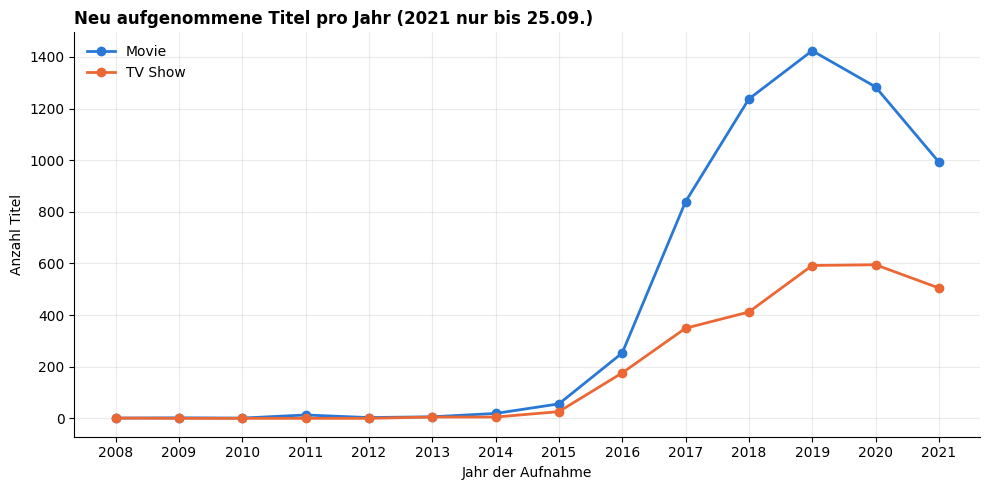

In [27]:
# Anzahl der Titel pro Jahr der Aufnahme und Typ
titles_per_year = (df_viz.groupby(["year_added", "type"], observed=True)
                   .size().unstack(fill_value=0))
display(titles_per_year)

fig, ax = plt.subplots()
for content_type, color in COLORS.items():
    ax.plot(titles_per_year.index.astype(int), titles_per_year[content_type],
            marker="o", markersize=6, linewidth=2, color=color, label=content_type)
ax.set_xticks(titles_per_year.index.astype(int))
ax.set_title("Neu aufgenommene Titel pro Jahr (2021 nur bis 25.09.)")
ax.set_xlabel("Jahr der Aufnahme")
ax.set_ylabel("Anzahl Titel")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 22. Ödev 2: En çok içerik üreten 10 ülke\nOrtak yapımlar her ülke için bir kez sayılır (`explode`). `Unknown` hariç. Uzun isimler için yatay bar.

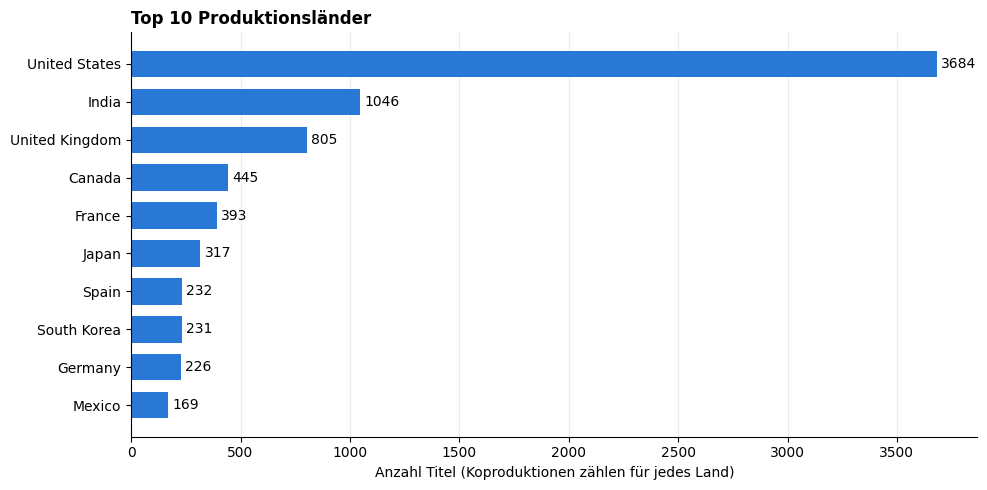

In [28]:
# Nur Titel aus df_viz berücksichtigen und unbekannte Länder ausschließen
countries = df_countries[df_countries["show_id"].isin(df_viz["show_id"])
                         & df_countries["country"].ne("Unknown")]
top_countries = countries["country"].value_counts().head(10)

fig, ax = plt.subplots()
bars = ax.barh(top_countries.index[::-1], top_countries.values[::-1], color="#2a78d6", height=0.7)
ax.bar_label(bars, padding=3)
ax.set_title("Top 10 Produktionsländer")
ax.set_xlabel("Anzahl Titel (Koproduktionen zählen für jedes Land)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 23. En yaygın 10 tür\nFilm ve dizi tür adları farklı olduğundan (`Dramas` / `TV Dramas`) iki ayrı grafik.

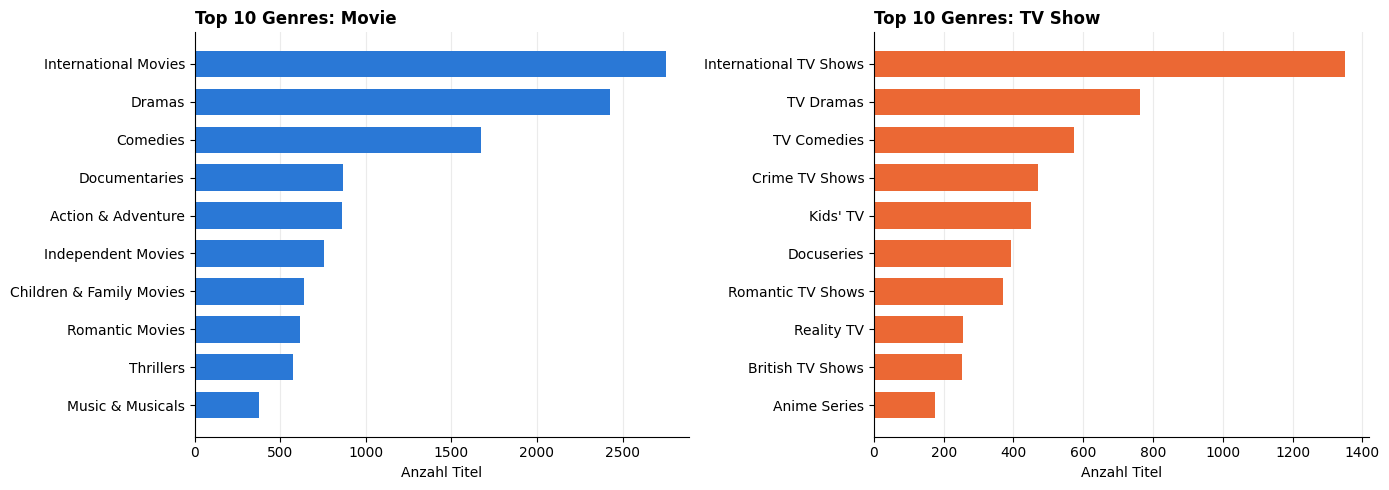

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (content_type, subset) in zip(axes, [("Movie", df_movies), ("TV Show", df_shows)]):
    top_genres = (df_genres[df_genres["show_id"].isin(subset["show_id"])]["genres"]
                  .value_counts().head(10))
    ax.barh(top_genres.index[::-1], top_genres.values[::-1], color=COLORS[content_type], height=0.7)
    ax.set_title(f"Top 10 Genres: {content_type}")
    ax.set_xlabel("Anzahl Titel")
    ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

## 24. Film süresi dağılımı\nSayısal dağılım için histogram. Medyan, aykırı değerlerden ortalamaya göre daha az etkilenir.

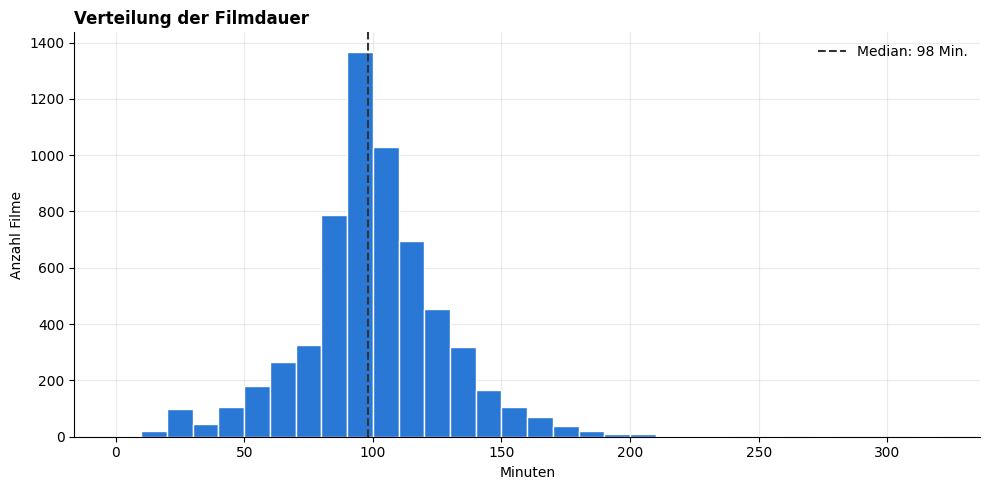

In [30]:
minutes = df_movies["duration_min"].to_numpy(dtype=float)
median_minutes = np.median(minutes)

fig, ax = plt.subplots()
ax.hist(minutes, bins=np.arange(0, minutes.max() + 10, 10),
        color=COLORS["Movie"], edgecolor="white", linewidth=1)
ax.axvline(median_minutes, color="#333333", linestyle="--", label=f"Median: {median_minutes:.0f} Min.")
ax.set_title("Verteilung der Filmdauer")
ax.set_xlabel("Minuten")
ax.set_ylabel("Anzahl Filme")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 25. Hedef kitleye göre dağılım\nFilm ve dizi sayıları farklı olduğundan adet yerine **yüzde** karşılaştırılır.

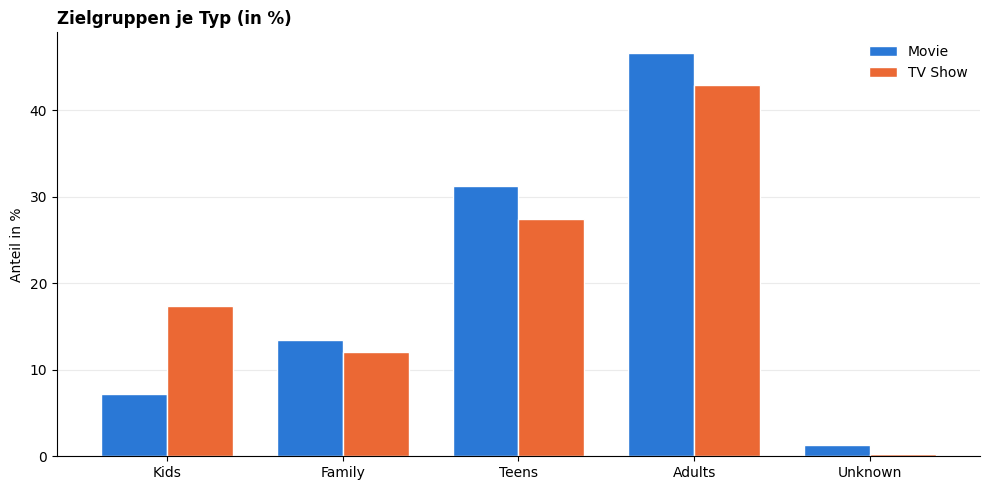

type,Movie,TV Show
audience,,
Kids,7.2,17.4
Family,13.5,12.0
Teens,31.3,27.4
Adults,46.7,42.9
Unknown,1.4,0.2


In [31]:
order = ["Kids", "Family", "Teens", "Adults", "Unknown"]
audience_pct = (pd.crosstab(df_viz["audience"].astype(str), df_viz["type"].astype(str),
                            normalize="columns")
                .reindex(order, fill_value=0) * 100)

# NR (Not Rated) fällt in die Gruppe Unknown
ax = audience_pct.plot(kind="bar", color=COLORS, width=0.75, edgecolor="white", linewidth=1)
ax.set_title("Zielgruppen je Typ (in %)")
ax.set_xlabel("")
ax.set_ylabel("Anteil in %")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="x", visible=False)
ax.legend(title="", frameon=False)
plt.tight_layout()
plt.show()
display(audience_pct.round(1))

## 26. Ödev 3: `clean_netflix(df)` fonksiyonu\nTüm adımlar tek fonksiyonda. Ham veriyi değiştirmez; yeni veri geldiğinde tek satırla çalışır.

In [32]:
def clean_netflix(df):
    # Bereinigt den Netflix-Rohdatensatz und gibt eine neue Kopie zurück
    df = df.copy()

    # 1. Spaltennamen
    df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")
    df = df.rename(columns={"listed_in": "genres", "cast": "cast_members"})

    # 2. Texte bereinigen
    text_cols = [col for col in df.columns if not pd.api.types.is_numeric_dtype(df[col])]
    for col in text_cols:
        df[col] = (df[col].str.replace("​", "", regex=False)
                   .str.replace(r"\s+", " ", regex=True).str.strip())
    for col in ["director", "cast_members", "country", "genres"]:
        df[col] = df[col].str.replace(r"^[,\s]+|[,\s]+$", "", regex=True)
    df[text_cols] = df[text_cols].replace("", np.nan)

    # 3. Duplikate
    df = df.drop_duplicates().drop_duplicates(subset="show_id", keep="first")

    # 4. Falsch einsortierte Werte
    mask = df["rating"].str.fullmatch(r"\d+ min", na=False) & df["duration"].isna()
    df.loc[mask, "duration"] = df.loc[mask, "rating"]
    df.loc[mask, "rating"] = np.nan
    df["rating"] = df["rating"].replace({"UR": "NR"})

    # 5. Fehlende Werte
    for col in ["director", "cast_members", "country"]:
        df[f"{col}_missing"] = df[col].isna()
    fill_cols = ["director", "cast_members", "country", "rating"]
    df[fill_cols] = df[fill_cols].fillna("Unknown")

    # 6. Datentypen
    df["date_added"] = pd.to_datetime(df["date_added"], format="%B %d, %Y", errors="coerce")
    value = pd.to_numeric(df["duration"].str.extract(r"(\d+)")[0], errors="coerce")
    df["duration_min"] = value.where(df["type"].eq("Movie")).astype("Int16")
    df["season_count"] = value.where(df["type"].eq("TV Show")).astype("Int16")

    # 7. Neue Merkmale
    df["year_added"] = df["date_added"].dt.year.astype("Int16")
    df["month_added"] = df["date_added"].dt.month.astype("Int8")
    df["years_to_netflix"] = df["year_added"] - df["release_year"]
    df["main_country"] = df["country"].str.split(",").str[0].str.strip()
    df["main_genre"] = df["genres"].str.split(",").str[0].str.strip()
    groups = {"Kids": ["TV-Y", "TV-Y7", "TV-Y7-FV", "G", "TV-G"], "Family": ["PG", "TV-PG"],
              "Teens": ["PG-13", "TV-14"], "Adults": ["R", "NC-17", "TV-MA"]}
    df["audience"] = np.select([df["rating"].isin(v) for v in groups.values()],
                               list(groups.keys()), default="Unknown")

    # 8. Prüfmarkierungen
    df["date_conflict"] = df["years_to_netflix"].lt(0).fillna(False).astype(bool)
    q1, q3 = np.percentile(df["duration_min"].dropna().to_numpy(dtype=float), [25, 75])
    iqr = q3 - q1
    outlier = df["duration_min"].lt(q1 - 1.5 * iqr) | df["duration_min"].gt(q3 + 1.5 * iqr)
    df["duration_outlier"] = outlier.fillna(False).astype(bool)

    # 9. Kategorien
    for col in ["type", "rating", "audience"]:
        df[col] = df[col].astype("category")
    return df

In [33]:
# Test: Die Funktion muss dasselbe Ergebnis liefern wie die Einzelschritte
df_function = clean_netflix(df_raw)
pd.testing.assert_frame_equal(df_function, df)
print("Funktion liefert identisches Ergebnis:", df_function.shape)

Funktion liefert identisches Ergebnis: (8807, 25)
